# Benchmark: carga y espacio de las estrategias de k-mers

**Responsable:** Juan Arias

**Objetivo:** comparar la estrategia principal (colección `kmers`, MODELO.md) con la alternativa embebida
(`tes_embebidos`) en tiempo de carga y espacio en disco. Los tiempos vienen de `03_pipeline_kmers.ipynb`
(`resultados/benchmark_carga.csv`). El benchmark de consultas está en `06_benchmark.ipynb` (Thomas).

Modelo de referencia: `../MODELO.md`

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pymongo import MongoClient

sys.path.insert(0, "..")
from src.benchmark import guardar_benchmark

DB_NAME = "panteon"
USUARIO = "juan"  # máquina donde se ejecutó 03_pipeline_kmers.ipynb
RESULTADOS = Path("../resultados")
FIGURAS = Path("../figuras")
FIGURAS.mkdir(exist_ok=True)

client = MongoClient("mongodb://localhost:27017")
db = client[DB_NAME]
db_bench = client[f"{DB_NAME}_bench"]

## 0. Máquina

Especificaciones de la máquina donde se midieron los tiempos (`scripts/specs_maquina.py`).

In [2]:
specs = json.loads((RESULTADOS / f"especificaciones_maquina_{USUARIO}.json").read_text(encoding="utf-8"))
cpu = specs["cpu"]
pd.Series({
    "Fecha": specs["fecha"],
    "Máquina": specs["maquina"],
    "CPU": f"{cpu['modelo']}, {cpu['nucleos_totales']} núcleos ({cpu['nucleos_rendimiento']} P + {cpu['nucleos_eficiencia']} E)",
    "RAM (GB)": specs["ram_gb"],
    "Sistema operativo": f"{specs['sistema_operativo']['nombre']} {specs['sistema_operativo']['version']}",
    "Disco": f"{specs['disco']['tipo']}, {specs['disco']['total_gb']} GB",
    "MongoDB": f"{specs['mongodb']['version']} ({specs['mongodb']['motor_almacenamiento']}, caché {specs['mongodb']['cache_wiredtiger_max_gb']} GB)",
    "Python": ", ".join(f"{k} {v}" for k, v in specs["python"].items()),
}).to_frame("valor")

,valor
Fecha,2026-10-25T23:05:04
Máquina,Sebastians-MacBook-Pro.local
CPU,"Apple M5, 10 núcleos (4 P + 6 E)"
RAM (GB),24.0
Sistema operativo,macOS 27.0.1
Disco,"SSD, 460.4 GB"
MongoDB,"7.0.45 (wiredTiger, caché 11.5 GB)"
Python,"version 3.11.17, pymongo 4.19.0, numpy 2.4.6, ..."


## 1. Tiempos de carga

In [3]:
TIEMPOS = ["t_calculo_s", "t_insercion_s", "t_indices_s", "t_total_s"]

carga = pd.read_csv(RESULTADOS / "benchmark_carga.csv")
carga = carga[carga["base"].isin([DB_NAME, db_bench.name])
              & carga["estrategia"].isin(["coleccion_kmers", "embebido_en_tes"])].reset_index(drop=True)
assert set(carga["estrategia"]) == {"coleccion_kmers", "embebido_en_tes"}, \
    f"Faltan filas de {DB_NAME} en benchmark_carga.csv: ejecutar 03_pipeline_kmers.ipynb"
carga["t_total_s"] = carga[["t_calculo_s", "t_insercion_s", "t_indices_s"]].sum(axis=1)
print(carga.sort_values(["estrategia", "repeticion"]).to_string(index=False))

# Media y desviación estándar muestral (ddof=1) por estrategia sobre las repeticiones
resumen = carga.groupby("estrategia")[TIEMPOS].agg(["mean", "std"]).round(3)
resumen.insert(0, ("repeticiones", ""), carga.groupby("estrategia")["repeticion"].nunique())
resumen

     estrategia          base  n_tes  n_docs  t_calculo_s  t_insercion_s  t_indices_s  repeticion  t_total_s
coleccion_kmers       panteon 239946 1439676      123.129         49.927       22.374           1    195.430
coleccion_kmers       panteon 239946 1439676      126.995         50.252       21.590           2    198.837
coleccion_kmers       panteon 239946 1439676      126.352         50.351       22.098           3    198.801
embebido_en_tes panteon_bench 239946  239946      125.410         47.953       11.696           1    185.059
embebido_en_tes panteon_bench 239946  239946      126.150         47.948       14.596           2    188.694
embebido_en_tes panteon_bench 239946  239946      125.877         47.833       13.015           3    186.725


repeticiones t_calculo_s        t_insercion_s         \
                                    mean    std          mean    std   
estrategia                                                             
coleccion_kmers            3     125.492  2.072        50.177  0.222   
embebido_en_tes            3     125.812  0.374        47.911  0.068   

                t_indices_s        t_total_s         
                       mean    std      mean    std  
estrategia                                           
coleccion_kmers      22.021  0.398   197.689  1.957  
embebido_en_tes      13.102  1.452   186.826  1.820

## 2. Espacio (`collStats`)

In [4]:
def estadisticas(base, coleccion, estrategia):
    st = base.command("collStats", coleccion)
    fila = {
        "estrategia": estrategia, "base": base.name, "coleccion": coleccion,
        "count": st["count"], "size": st["size"], "avgObjSize": st.get("avgObjSize", 0),
        "storageSize": st["storageSize"], "totalIndexSize": st["totalIndexSize"],
    }
    fila.update({f"idx_{nombre}": tam for nombre, tam in st["indexSizes"].items()})
    return fila


espacio = pd.DataFrame([
    estadisticas(db, "kmers", "coleccion_kmers"),
    estadisticas(db_bench, "tes_embebidos", "embebido_en_tes"),
    estadisticas(db, "tes", "referencia_tes"),
])
guardar_benchmark(espacio.to_dict("records"), RESULTADOS / "benchmark_espacio.csv")
espacio.T

,0,1,2
estrategia,coleccion_kmers,embebido_en_tes,referencia_tes
base,panteon,panteon_bench,panteon
coleccion,kmers,tes_embebidos,tes
count,1439676,239946,239946
size,8144577956,8104036854,73969252
avgObjSize,5657,33774,308
storageSize,3177865216,3184594944,12718080
totalIndexSize,60469248,5435392,10919936
idx__id_,15781888,2490368,2404352
idx_te_id_1_k_1,16445440.0,NaN,NaN


`size` es el tamaño sin comprimir de los documentos; `storageSize` es lo que ocupan en disco con la compresión de WiredTiger. Todos los tamaños están en bytes. `tes` es solo referencia: la estrategia embebida contiene una copia de `tes` más los k-mers. El espacio se mide una sola vez sobre las colecciones de la última repetición: es determinista para los mismos datos, así que la figura de espacio no lleva barras de error.

## 3. Figuras

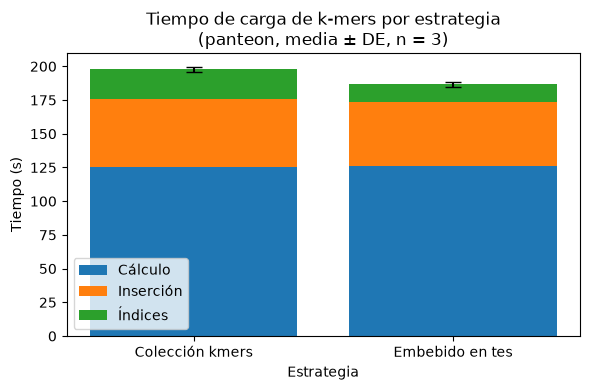

In [5]:
NOMBRES = {"coleccion_kmers": "Colección kmers", "embebido_en_tes": "Embebido en tes", "referencia_tes": "tes (referencia)"}

medias = carga.groupby("estrategia")[TIEMPOS].mean()
desv = carga.groupby("estrategia")[TIEMPOS].std()
n_rep = carga.groupby("estrategia")["repeticion"].nunique().min()

fig, ax = plt.subplots(figsize=(6, 4))
etiquetas = medias.index.map(NOMBRES)
abajo = 0
for columna, nombre in [("t_calculo_s", "Cálculo"), ("t_insercion_s", "Inserción"), ("t_indices_s", "Índices")]:
    ax.bar(etiquetas, medias[columna], bottom=abajo, label=nombre)
    abajo = abajo + medias[columna]
# Barra de error: desviación estándar del tiempo total entre repeticiones
ax.errorbar(etiquetas, medias["t_total_s"], yerr=desv["t_total_s"], fmt="none", ecolor="black", capsize=6)
ax.set_title(f"Tiempo de carga de k-mers por estrategia\n({DB_NAME}, media ± DE, n = {n_rep})")
ax.set_xlabel("Estrategia")
ax.set_ylabel("Tiempo (s)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / f"benchmark_carga_{DB_NAME}.png", dpi=300)
plt.show()

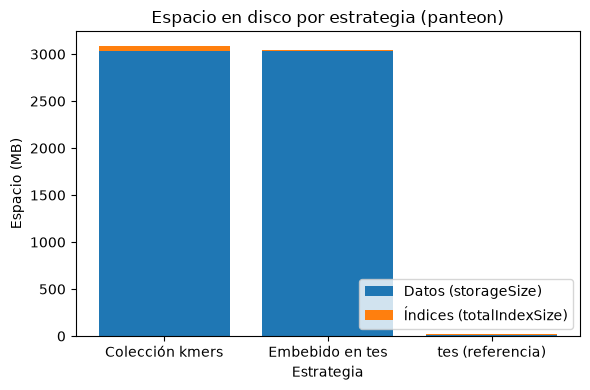

In [6]:
MB = 1024 ** 2
fig, ax = plt.subplots(figsize=(6, 4))
etiquetas = espacio["estrategia"].map(NOMBRES)
ax.bar(etiquetas, espacio["storageSize"] / MB, label="Datos (storageSize)")
ax.bar(etiquetas, espacio["totalIndexSize"] / MB, bottom=espacio["storageSize"] / MB, label="Índices (totalIndexSize)")
ax.set_title(f"Espacio en disco por estrategia ({DB_NAME})")
ax.set_xlabel("Estrategia")
ax.set_ylabel("Espacio (MB)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / f"benchmark_espacio_{DB_NAME}.png", dpi=300)
plt.show()

## 4. Interpretación

Cifras de `panteon` (239.946 TEs), máquina de la sección 0. Tamaños en MB de 1024² bytes; tiempos en segundos,
media ± desviación estándar de 3 repeticiones completas de `03_pipeline_kmers.ipynb`. Ambas estrategias
se cargan con validación `$jsonSchema` (`kmers` con `ESQUEMA_KMERS`; `tes_embebidos` con el validador de `tes`
más el perfil `kmers.k1`–`k6`), así que la inserción es comparable.

**Espacio en datos: prácticamente igual.** `kmers` ocupa 3.030,6 MB en disco (`storageSize`) y
`tes_embebidos` 3.037,1 MB; sin comprimir, 7.767,3 MB frente a 7.728,6 MB. La embebida incluye una copia de
`tes` (12,1 MB en disco), así que la parte de k-mers queda en unos 3.025 MB, apenas 0,2 % menos que `kmers`:
repetir `te_id`, `pdb_id`, `te_order` y `k` en 1,44 millones de documentos cuesta poco tras la compresión.

**Espacio en índices: `kmers` ocupa unas 11 veces más.** 57,7 MB (`_id` 15,1; `{te_id, k}` 15,7;
`{pdb_id, k}` 19,4; `{k, te_order}` 7,5) frente a 5,2 MB de `tes_embebidos` (`_id` 2,4; `{pdb_id}` 2,8),
porque indexa 1.439.676 entradas en lugar de 239.946. Aun así, los índices son menos del 2 % del total.

**Carga: la embebida es un 5 % más rápida.** `kmers` tarda 197,7 ± 2,0 s (cálculo 125,5 ± 2,1; inserción
50,2 ± 0,2; índices 22,0 ± 0,4) y la embebida 186,8 ± 1,8 s (125,8 ± 0,4; 47,9 ± 0,1; 13,1 ± 1,5). El cálculo
es igual en ambas; la diferencia está casi toda en los índices (8,9 s) y un poco en la inserción (2,3 s). Las
tres repeticiones son estables (desviación ≤ 2 s en el total). Son unos 11 s en una carga que se hace una vez,
así que el tiempo de carga no decide la estrategia.

**Según el tipo de uso** (a confirmar con el benchmark de consultas de Thomas, `06_benchmark.ipynb`):

- **Un k para muchos TEs** (heatmap de 2-mers por orden, consultas sobre un solo k): favorece `kmers`. El
  índice `{k, te_order}` lleva directo a los documentos de ese k (5,7 KB de media entre todos los k). En la
  embebida cada TE es un documento de 33,8 KB de media y hay que leerlo entero aunque se proyecte solo `kmers.k2`.
- **Todos los k de un TE** (perfil completo, consulta 15): favorece la embebida, que lo resuelve con una sola
  lectura por `pdb_id`; en `kmers` son 6 documentos por `{pdb_id, k}`, igualmente rápido para un TE.

Con espacio casi igual y una diferencia de carga pequeña, la elección la decide el patrón de
consultas: si dominan las agregaciones por k, como en el proyecto, conviene mantener la colección `kmers` de MODELO.md.

Las cifras de `panteon_prueba` (25 TEs) siguen en los CSV y solo sirvieron para validar el notebook.